# Use Case 4: Reporting from MySQL

This notebook stores, queries and presents results straight from MySQL.

```
 chicago_crime (fact)  ──►  summary tables  ──►  SQL queries  ──►  views  ──►  pd.read_sql  ──►  charts
   (loaded in UC1)          (mysql-connector)                     vw_crime_yearly
                                                                  vw_crime_by_category
```

All the numbers here come from MySQL, not from the pickle file. The assignment asks for the Python MySQL Connector (`mysql-connector-python`) to create and load tables, so that's what I use.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display

import crime_utils as cu

cu.set_style()

## Connecting with mysql-connector
The login details are read from `.env` (see the README). Passwords shouldn't be written into a notebook.

In [2]:
cnx = cu.get_mysql_connection()
cur = cnx.cursor()
cur.execute("SELECT VERSION(), DATABASE(), (SELECT COUNT(*) FROM chicago_crime)")
version, db, n = cur.fetchone()
print(f"Connected to MySQL {version} | database = {db} | chicago_crime rows = {n:,}")

Connected to MySQL 8.4.7 | database = chicago_crime_db | chicago_crime rows = 498


## 1. Create and fill the summary tables

Summary tables hold results that are already calculated, so a dashboard doesn't have to scan the whole fact table each time. I make three:

| Table | One row per | Columns |
|---|---|---|
| `summary_crime_yearly` | year | total crimes, arrests, arrest rate, domestic crimes |
| `summary_crime_category` | crime type | total, % of all crimes, arrests, arrest rate |
| `summary_community` | community area (all 77, including areas with no crimes) | name, population, total, crimes per 1,000 residents |

How this works with mysql-connector:
* `cursor.execute(sql)` runs a single statement.
* `INSERT ... SELECT` does the aggregation inside MySQL and inserts the result in one go, so the data never has to come back to Python.
* `cnx.commit()` saves the changes. mysql-connector doesn't auto-commit by default.

`summary_community` starts from `city_community` and LEFT JOINs the crimes, with `COUNT(c.case_number)` so an area with no crimes gets 0. An INNER JOIN would silently drop those areas, and any average over the table would then be too high.

In [3]:
DDL = {
    "summary_crime_yearly": """
        CREATE TABLE summary_crime_yearly (
            year            SMALLINT     NOT NULL PRIMARY KEY,
            total_crimes    INT          NOT NULL,
            total_arrests   INT          NOT NULL,
            arrest_rate_pct DECIMAL(5,2) NOT NULL,
            domestic_crimes INT          NOT NULL)""",
    "summary_crime_category": """
        CREATE TABLE summary_crime_category (
            primary_type    VARCHAR(64)  NOT NULL PRIMARY KEY,
            total_crimes    INT          NOT NULL,
            pct_of_total    DECIMAL(5,2) NOT NULL,
            total_arrests   INT          NOT NULL,
            arrest_rate_pct DECIMAL(5,2) NOT NULL)""",
    "summary_community": """
        CREATE TABLE summary_community (
            community_code      INT          NOT NULL PRIMARY KEY,
            community_name      VARCHAR(64)  NOT NULL,
            population          INT,
            total_crimes        INT          NOT NULL,
            crimes_per_1000_pop DECIMAL(10,2))""",
}

LOAD = {
    "summary_crime_yearly": """
        INSERT INTO summary_crime_yearly
        SELECT year, COUNT(*), SUM(arrest), ROUND(100 * AVG(arrest), 2), SUM(domestic)
        FROM chicago_crime GROUP BY year""",
    "summary_crime_category": """
        INSERT INTO summary_crime_category
        SELECT i.primary_type, COUNT(*),
               ROUND(100 * COUNT(*) / (SELECT COUNT(*) FROM chicago_crime), 2),
               SUM(c.arrest), ROUND(100 * AVG(c.arrest), 2)
        FROM chicago_crime c JOIN iucr i ON i.iucr_code = c.iucr_code
        GROUP BY i.primary_type""",
    "summary_community": """
        INSERT INTO summary_community
        SELECT cc.community_code, cc.community_name, cc.population, COUNT(c.case_number),
               ROUND(1000 * COUNT(c.case_number) / NULLIF(cc.population, 0), 2)
        FROM city_community cc
        LEFT JOIN chicago_crime c ON c.community_code = cc.community_code
        GROUP BY cc.community_code, cc.community_name, cc.population""",
}

try:
    for table in DDL:
        cur.execute(f"DROP TABLE IF EXISTS {table}")
        cur.execute(DDL[table])
        cur.execute(LOAD[table])
        print(f"{table:<24} created and loaded: {cur.rowcount:>3} rows")
    cnx.commit()
except Exception:
    # this only undoes uncommitted INSERTs. DROP/CREATE TABLE commit automatically in MySQL,
    # so a failure might leave a table dropped or empty. Just fix the problem and run this cell again
    cnx.rollback()
    raise

summary_crime_yearly     created and loaded:   5 rows
summary_crime_category   created and loaded:  23 rows
summary_community        created and loaded:  77 rows


**Inserting from Python with parameters.** When the data comes from Python rather than another table, I use `executemany` with `%s` placeholders. The driver escapes the values properly. Building SQL by joining strings together is how SQL injection happens, so I avoid that.

In [4]:
cur.execute("DROP TABLE IF EXISTS etl_run_log")
cur.execute("""CREATE TABLE etl_run_log (
                   step VARCHAR(40) PRIMARY KEY, rows_written INT, run_at DATETIME)""")
cur.execute("SELECT COUNT(*) FROM summary_crime_yearly"); r1 = cur.fetchone()[0]
cur.execute("SELECT COUNT(*) FROM summary_crime_category"); r2 = cur.fetchone()[0]
cur.execute("SELECT COUNT(*) FROM summary_community"); r3 = cur.fetchone()[0]
now = pd.Timestamp.now().to_pydatetime().replace(microsecond=0)
rows = [("summary_crime_yearly", r1, now), ("summary_crime_category", r2, now),
        ("summary_community", r3, now)]
cur.executemany("INSERT INTO etl_run_log (step, rows_written, run_at) VALUES (%s, %s, %s)", rows)
cnx.commit()
print(f"etl_run_log: {cur.rowcount} rows inserted with executemany")

etl_run_log: 3 rows inserted with executemany


A small helper that runs a query with mysql-connector and returns a DataFrame (the column names come from `cursor.description`).

In [5]:
def query_df(sql, params=None):
    c = cnx.cursor()
    c.execute(sql, params or ())
    out = pd.DataFrame(c.fetchall(), columns=[d[0] for d in c.description])
    c.close()
    return out

display(query_df("SELECT * FROM summary_crime_yearly ORDER BY year"))

,year,total_crimes,total_arrests,arrest_rate_pct,domestic_crimes
0,2012,2,2,100.00,0
1,2013,1,1,100.00,0
2,2014,1,0,0.00,0
3,2015,4,2,50.00,1
4,2016,490,119,24.29,67


## 2. MySQL queries
### 2a. Crimes per year

In [6]:
q_year = """
SELECT year, COUNT(*) AS crime_count
FROM chicago_crime
GROUP BY year
ORDER BY year"""
display(query_df(q_year))

,year,crime_count
0,2012,2
1,2013,1
2,2014,1
3,2015,4
4,2016,490


### 2b. Top 5 crime types and their share
`SUM(COUNT(*)) OVER ()` is a window function. It adds up the counts across all groups to get the overall total, but keeps each row, so every row can be divided by that total. It runs before `LIMIT`, which means the percentage is out of all crimes and not just the top 5.

In [7]:
q_top5 = """
SELECT i.primary_type,
       COUNT(*)                                         AS crime_count,
       ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_total
FROM chicago_crime c
JOIN iucr i ON i.iucr_code = c.iucr_code
GROUP BY i.primary_type
ORDER BY crime_count DESC
LIMIT 5"""
top5 = query_df(q_top5)
display(top5)
print(f"Top 5 together = {top5['pct_of_total'].astype(float).sum():.2f}% of all crimes")

,primary_type,crime_count,pct_of_total
0,THEFT,105,21.08
1,BATTERY,85,17.07
2,CRIMINAL DAMAGE,49,9.84
3,OTHER OFFENSE,39,7.83
4,DECEPTIVE PRACTICE,38,7.63


Top 5 together = 63.45% of all crimes


### 2c. Arrests per year
`arrest` is stored as 0 or 1, so `SUM(arrest)` gives the number of arrests and `AVG(arrest)` gives the arrest rate.

In [8]:
q_arrest = """
SELECT year,
       SUM(arrest)                 AS arrest_count,
       COUNT(*)                    AS crime_count,
       ROUND(100 * AVG(arrest), 2) AS arrest_rate_pct
FROM chicago_crime
GROUP BY year
ORDER BY year"""
display(query_df(q_arrest))

,year,arrest_count,crime_count,arrest_rate_pct
0,2012,2,2,100.00
1,2013,1,1,100.00
2,2014,0,1,0.00
3,2015,2,4,50.00
4,2016,119,490,24.29


## 3. Views
A view is a saved query that you can use like a table. It doesn't store any data itself; it runs the query each time you read from it, so it's always current. Using `CREATE OR REPLACE` means the script can be run more than once without errors.

In [9]:
VIEWS = {
    "vw_crime_yearly": """
        CREATE OR REPLACE VIEW vw_crime_yearly AS
        SELECT year,
               COUNT(*)                    AS total_crimes,
               SUM(arrest)                 AS total_arrests,
               ROUND(100 * AVG(arrest), 2) AS arrest_rate_pct,
               SUM(domestic)               AS domestic_crimes
        FROM chicago_crime
        GROUP BY year""",
    "vw_crime_by_category": """
        CREATE OR REPLACE VIEW vw_crime_by_category AS
        SELECT i.primary_type,
               COUNT(*)                                         AS total_crimes,
               ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_total,
               SUM(c.arrest)                                    AS total_arrests,
               ROUND(100 * AVG(c.arrest), 2)                    AS arrest_rate_pct
        FROM chicago_crime c
        JOIN iucr i ON i.iucr_code = c.iucr_code
        GROUP BY i.primary_type""",
}
for name, ddl in VIEWS.items():
    cur.execute(ddl)
    print(f"View {name} created")
cnx.commit()

display(query_df("""SELECT TABLE_NAME, TABLE_TYPE FROM information_schema.TABLES
                    WHERE TABLE_SCHEMA = DATABASE() ORDER BY TABLE_TYPE, TABLE_NAME"""))

View vw_crime_yearly created
View vw_crime_by_category created


,TABLE_NAME,TABLE_TYPE
0,chicago_crime,BASE TABLE
1,city_community,BASE TABLE
2,district_ps_info,BASE TABLE
3,etl_run_log,BASE TABLE
4,iucr,BASE TABLE
5,police_beat_info,BASE TABLE
6,summary_community,BASE TABLE
7,summary_crime_category,BASE TABLE
8,summary_crime_yearly,BASE TABLE
9,ward_office,BASE TABLE


## 4. Reading the views into Pandas

The assignment uses `pd.read_sql("SELECT * FROM vw_crime_yearly", conn)`. Pandas officially supports SQLAlchemy connections (a raw mysql-connector connection works too, but it prints a warning), so here `conn` is a SQLAlchemy connection.

In [10]:
from sqlalchemy import text

engine = cu.get_engine()
with engine.connect() as conn:
    yearly = pd.read_sql(text("SELECT * FROM vw_crime_yearly ORDER BY year"), conn)
    by_cat = pd.read_sql(text("SELECT * FROM vw_crime_by_category ORDER BY total_crimes DESC"), conn)
    community = pd.read_sql(text("SELECT * FROM summary_community ORDER BY total_crimes DESC"), conn)

# DECIMAL and SUM() results from MySQL can come back as Decimal objects or floats like 2.0, so convert them to normal numbers
for frame in (yearly, by_cat, community):
    for c in frame.columns:
        if c in ("primary_type", "community_name"):
            continue
        frame[c] = pd.to_numeric(frame[c])
        if frame[c].notna().all() and (frame[c] % 1 == 0).all():   # whole numbers -> int
            frame[c] = frame[c].astype(int)

display(yearly)
display(by_cat.head(10))

,year,total_crimes,total_arrests,arrest_rate_pct,domestic_crimes
0,2012,2,2,100.00,0
1,2013,1,1,100.00,0
2,2014,1,0,0.00,0
3,2015,4,2,50.00,1
4,2016,490,119,24.29,67


,primary_type,total_crimes,pct_of_total,total_arrests,arrest_rate_pct
0,THEFT,105,21.08,10,9.52
1,BATTERY,85,17.07,20,23.53
2,CRIMINAL DAMAGE,49,9.84,2,4.08
3,OTHER OFFENSE,39,7.83,8,20.51
4,DECEPTIVE PRACTICE,38,7.63,5,13.16
5,ASSAULT,35,7.03,10,28.57
6,NARCOTICS,32,6.43,32,100.00
7,ROBBERY,30,6.02,6,20.00
8,CRIMINAL TRESPASS,17,3.41,15,88.24
9,MOTOR VEHICLE THEFT,16,3.21,0,0.00


Some more analysis in Pandas on the data pulled from MySQL, such as the change from one year to the next and each category's share of all arrests.

In [11]:
yearly["yoy_change_%"] = yearly["total_crimes"].pct_change().mul(100).round(1)
yearly["domestic_share_%"] = (yearly["domestic_crimes"] / yearly["total_crimes"] * 100).round(1)
by_cat["share_of_all_arrests_%"] = (by_cat["total_arrests"] / by_cat["total_arrests"].sum() * 100).round(1)
display(yearly[["year", "total_crimes", "yoy_change_%", "arrest_rate_pct", "domestic_share_%"]])
if (yearly["total_crimes"] < 30).any():
    print("Note: years with very few crimes make % changes meaningless (e.g. 4 → 490 crimes = +12,150%). "
          "Read yoy_change_% only for years with substantial, comparable data.")
display(by_cat[["primary_type", "total_crimes", "pct_of_total", "arrest_rate_pct",
                "share_of_all_arrests_%"]].head(10))

,year,total_crimes,yoy_change_%,arrest_rate_pct,domestic_share_%
0,2012,2,NaN,100.00,0.0
1,2013,1,-50.0,100.00,0.0
2,2014,1,0.0,0.00,0.0
3,2015,4,300.0,50.00,25.0
4,2016,490,12150.0,24.29,13.7


Note: years with very few crimes make % changes meaningless (e.g. 4 → 490 crimes = +12,150%). Read yoy_change_% only for years with substantial, comparable data.


,primary_type,total_crimes,pct_of_total,arrest_rate_pct,share_of_all_arrests_%
0,THEFT,105,21.08,9.52,8.1
1,BATTERY,85,17.07,23.53,16.1
2,CRIMINAL DAMAGE,49,9.84,4.08,1.6
3,OTHER OFFENSE,39,7.83,20.51,6.5
4,DECEPTIVE PRACTICE,38,7.63,13.16,4.0
5,ASSAULT,35,7.03,28.57,8.1
6,NARCOTICS,32,6.43,100.00,25.8
7,ROBBERY,30,6.02,20.00,4.8
8,CRIMINAL TRESPASS,17,3.41,88.24,12.1
9,MOTOR VEHICLE THEFT,16,3.21,0.00,0.0


## 5. Charts from the MySQL data

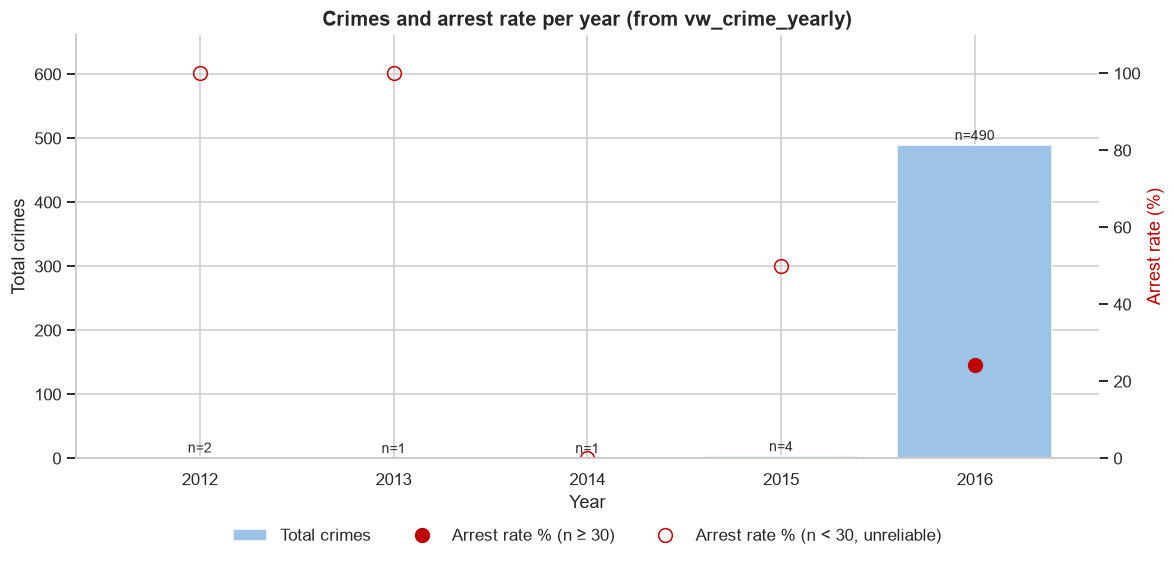

Years with fewer than 30 crimes (hollow markers): 2012 (n=2, 100%), 2013 (n=1, 100%), 2014 (n=1, 0%), 2015 (n=4, 50%). Their rates swing between 0% and 100% by chance, so don't read them; notebook 02 reaches the same conclusion.


In [12]:
MIN_N = 30          # below this a yearly arrest rate is mostly noise (same rule as notebook 02)
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(yearly["year"], yearly["total_crimes"], color="#9dc3e6", label="Total crimes")
for x_, n_ in zip(yearly["year"], yearly["total_crimes"]):
    ax1.annotate(f"n={n_}", (x_, n_), textcoords="offset points", xytext=(0, 3), ha="center", fontsize=9)
ax1.set(xlabel="Year", ylabel="Total crimes", title="Crimes and arrest rate per year (from vw_crime_yearly)")
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax1.set_xticks(yearly["year"])
ax1.set_ylim(0, yearly["total_crimes"].max() * 1.35)
ax2 = ax1.twinx()                                   # second y-axis for the rate
ok = yearly["total_crimes"] >= MIN_N
ax2.plot(yearly.loc[ok, "year"], yearly.loc[ok, "arrest_rate_pct"], color="#c00000", marker="o",
         linestyle="none", markersize=9, label=f"Arrest rate % (n ≥ {MIN_N})")
ax2.plot(yearly.loc[~ok, "year"], yearly.loc[~ok, "arrest_rate_pct"], color="#c00000", marker="o",
         markerfacecolor="none", linestyle="none", markersize=9, label=f"Arrest rate % (n < {MIN_N}, unreliable)")
ax2.set_ylabel("Arrest rate (%)", color="#c00000")
ax2.set_ylim(0, 110)
ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False)
cu.save_fig(fig, "uc4_01_yearly_from_mysql")
plt.show()
few = yearly.loc[~ok, ["year", "total_crimes", "arrest_rate_pct"]]
if len(few):
    print("Years with fewer than {} crimes (hollow markers): {}. Their rates swing between 0% and 100% "
          "by chance, so don't read them; notebook 02 reaches the same conclusion.".format(
              MIN_N, ", ".join(f"{y} (n={n}, {r:.0f}%)" for y, n, r in few.itertuples(index=False))))

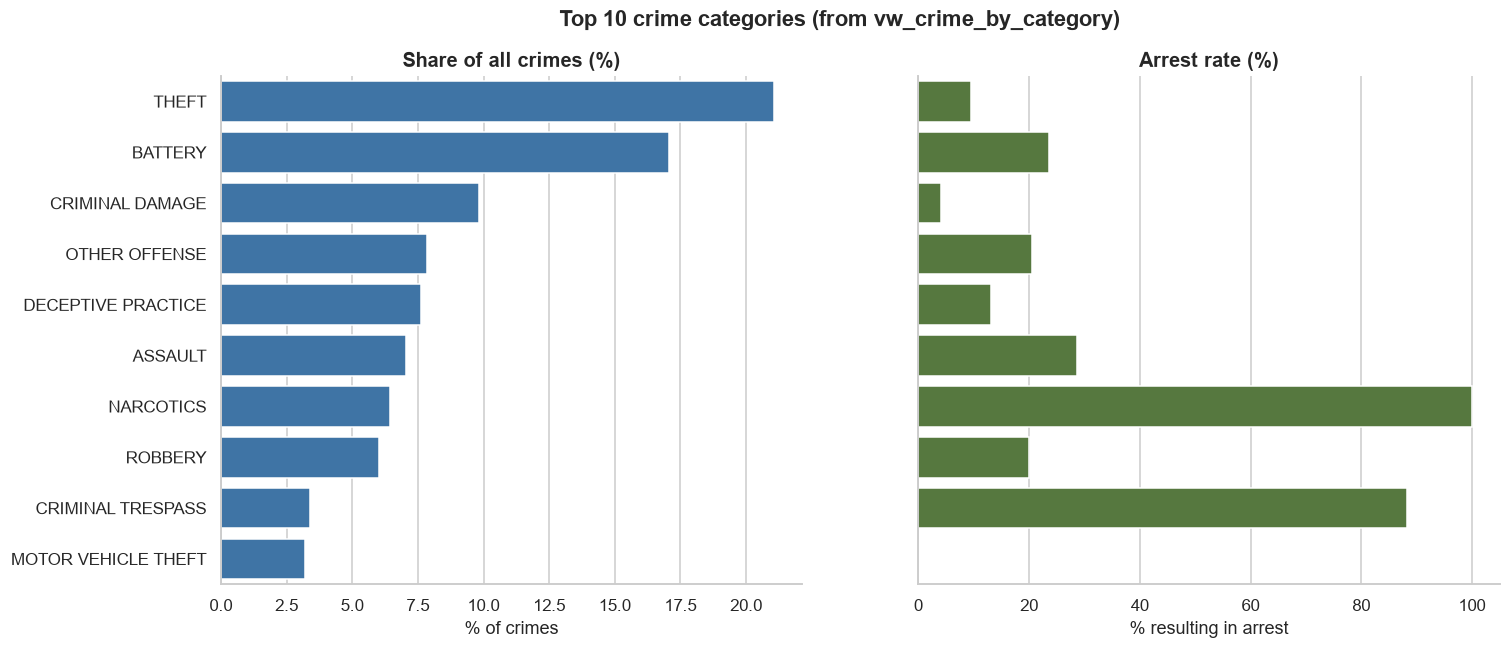

In [13]:
top = by_cat.head(10)
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
sns.barplot(data=top, x="pct_of_total", y="primary_type", ax=axes[0], color="#2e75b6")
axes[0].set(title="Share of all crimes (%)", xlabel="% of crimes", ylabel="")
sns.barplot(data=top, x="arrest_rate_pct", y="primary_type", ax=axes[1], color="#548235")
axes[1].set(title="Arrest rate (%)", xlabel="% resulting in arrest", ylabel="")
fig.suptitle("Top 10 crime categories (from vw_crime_by_category)", fontweight="bold")
cu.save_fig(fig, "uc4_02_categories_from_mysql")
plt.show()

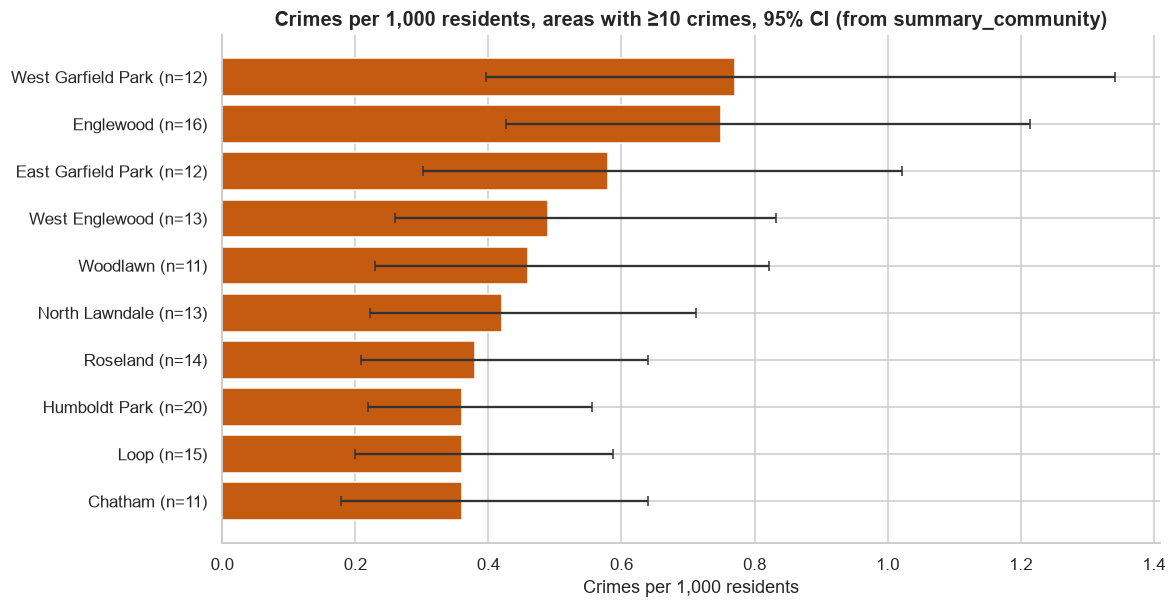

77 areas in summary_community; 17 have at least 10 crimes and are ranked. The intervals overlap heavily, so the order within this list is not reliable.
Residents are the wrong denominator for the Loop and Near North Side: most people there on a given day are commuters and visitors, so their per-resident rates overstate the risk.


In [14]:
MIN_CRIMES = 10     # a rate built on 2 or 3 crimes is mostly noise
eligible = community[community["total_crimes"] >= MIN_CRIMES]
top_pc = eligible.nlargest(10, "crimes_per_1000_pop").reset_index(drop=True)
lo, hi = cu.poisson_ci(top_pc["total_crimes"])
rate = top_pc["crimes_per_1000_pop"]
top_pc["ci_low"] = lo / top_pc["population"] * 1000
top_pc["ci_high"] = hi / top_pc["population"] * 1000

fig, ax = plt.subplots(figsize=(11, 6))
y = range(len(top_pc))
ax.barh(y, rate, xerr=[rate - top_pc["ci_low"], top_pc["ci_high"] - rate],
        color="#c55a11", ecolor="#333333", capsize=3)
ax.set_yticks(list(y), [f"{name.title()} (n={n_})" for name, n_ in
                        zip(top_pc["community_name"], top_pc["total_crimes"])])
ax.invert_yaxis()
ax.set(title=f"Crimes per 1,000 residents, areas with ≥{MIN_CRIMES} crimes, 95% CI (from summary_community)",
       xlabel="Crimes per 1,000 residents", ylabel="")
cu.save_fig(fig, "uc4_03_community_per_capita_from_mysql")
plt.show()
print(f"{len(community)} areas in summary_community; {len(eligible)} have at least {MIN_CRIMES} crimes and are ranked. "
      "The intervals overlap heavily, so the order within this list is not reliable.")
print("Residents are the wrong denominator for the Loop and Near North Side: most people there on a "
      "given day are commuters and visitors, so their per-resident rates overstate the risk.")

## Closing the connections
It's good practice to close cursors and connections when you're done, since open connections take up server resources.

In [15]:
cur.close()
cnx.close()
engine.dispose()
print("Connections closed")

Connections closed
